# 5% 600K PEG — Manual Ground Truth vs Automated Reproducibility ($K$, $n$)

**Goal.** Establish Ostwald–de Waele parameters $K$ and $n$ for a 5% 600K PEG formulation from a long manual cone–plate sweep, then compare six automated platform repeats. Decide whether the observed **$>20\%$ $K$ drift** (with nearly stable $n$) is primarily a **data-acquisition** problem or a **curve-fitting** problem, targeting **$\le 10\%$ error**.

**Data**
- Manual (≈3 h 15 min): `results/auto_runs/5%600KPEG_MANUAL_RAW.csv`
- Automated reproducibility (6 experiments, 2 timestamps): `results/auto_runs/5%600K_PEG_reproducibility_20261119.csv`

**Precedent.** Newtonian silicones were unreliable under polynomial gap fits until the team switched to a **hyperbolic** drag model $D(h)=A/(h+h_c)+B$ (and the APP_V4 form $D=a/|h-b|$). That history is the calibration analogy for this polymer study.

**Geometry (important for comparing the two campaigns).**
- Manual table `Increment`: **1 step = 13 μm = 0.013 mm** (gap closes as increment decreases).
- Automated CNC `Z_Height_mm`: machine millimetres — a change from $Z=-64$ to $Z=-65$ is **1 mm** of travel. Typical feedback step in these runs is $\Delta Z \approx 0.02\,\mathrm{mm} = 20\,\mu\mathrm{m} \approx 1.5$ manual increments.


## 1. Setup

Uses the production rheology stack (`fit_stress_powerlaw`, `predict_cell_rheology`, three-pathway characterization) so automated $K$, $n$ match what the live system reports.


In [1]:
from __future__ import annotations

import sys
from pathlib import Path
from typing import Any, Dict, List, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import curve_fit

NOTEBOOK_DIR = Path.cwd().resolve()
ROOT = None
for candidate in [NOTEBOOK_DIR, NOTEBOOK_DIR.parent, NOTEBOOK_DIR.parent.parent]:
    if (candidate / "src" / "viscometry").is_dir():
        ROOT = candidate
        break
if ROOT is None:
    ROOT = NOTEBOOK_DIR.parents[1]

sys.path.insert(0, str(ROOT / "src"))

from viscometry.rheology.constants import (
    H_C_UNIVERSAL_MM,
    PCT_TO_PA,
    SILICONE_K,
    SILICONE_P,
    shear_rate,
)
from viscometry.rheology.live_adapter import (
    filter_measurement_points,
    predict_cell_rheology,
)
from viscometry.rheology.stress_powerlaw import fit_stress_powerlaw

MANUAL_CSV = ROOT / "results/auto_runs/5%600KPEG_MANUAL_RAW.csv"
AUTO_CSV = ROOT / "results/auto_runs/5%600K_PEG_reproducibility_20261119.csv"
G_REF = 20.0  # s^-1 — interior of both manual and auto shear-rate windows

# Physical geometry: manual Increment vs automated CNC Z
MANUAL_INC_MM = 0.013  # 13 microns per increment
# Automated Z_Height_mm is already in mm (Z=-64 -> Z=-65 is 1 mm travel)

print(f"ROOT = {ROOT}")
print(f"SILICONE_K={SILICONE_K:.3e}  SILICONE_P={SILICONE_P}  hc={H_C_UNIVERSAL_MM}")
print(f"PCT_TO_PA={PCT_TO_PA:.6f}  G_REF={G_REF} 1/s")
print(f"Manual step = {MANUAL_INC_MM*1000:.0f} um ({MANUAL_INC_MM} mm); auto Z is in mm")
assert MANUAL_CSV.exists() and AUTO_CSV.exists()


ROOT = /Users/ianng/Documents/GitHub/Automated_Viscometry
SILICONE_K=3.000e-04  SILICONE_P=1.0  hc=0.2774
PCT_TO_PA=1.985845  G_REF=20.0 1/s
Manual step = 13 um (0.013 mm); auto Z is in mm


## 2. Loaders

### Manual
Brookfield-style table: shear rate `SR_1/s`, shear stress `SS_dyne/cm2`, viscosity cP. Convert stress to Pa via $1\,\mathrm{Pa}=10\,\mathrm{dyne/cm^2}$. One missing `SS` cell (inc 13, 13 rpm) is reconstructed from the instrument convention $\eta_{\mathrm{cP}}=100\,\tau_{\mathrm{dyne/cm^2}}/\dot\gamma$.

### Automated
The reproducibility CSV concatenates two run timestamps and five cells (cell 7 appears in both). We split on timestamp + cell into **6 independent experiments**. `Z_Height_mm` is CNC millimetres (moving from $-64$ to $-65$ is 1 mm of gap closure).


In [2]:
def load_manual(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path)
    df["Formulation"] = df["Formulation"].ffill()
    for col in ["Increment", "speed_RPM", "SR_1/s", "Viscosity_cP", "Torque_%", "SS_dyne/cm2", "Accuracy_cP"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    missing = df["SS_dyne/cm2"].isna()
    df.loc[missing, "SS_dyne/cm2"] = (
        df.loc[missing, "Viscosity_cP"] * df.loc[missing, "SR_1/s"] / 100.0
    )
    df["tau_Pa"] = df["SS_dyne/cm2"] / 10.0
    df["gamma_dot_1_s"] = df["SR_1/s"]
    df["drag"] = df["Torque_%"] / df["speed_RPM"]
    return df


def load_auto_experiments(path: Path) -> List[Dict[str, Any]]:
    raw = path.read_text().splitlines()
    chunks: List[pd.DataFrame] = []
    cur_ts = None
    header = None
    buf: List[List[str]] = []

    def flush() -> None:
        nonlocal buf
        if buf and header is not None:
            d = pd.DataFrame(buf, columns=header)
            d["timestamp"] = cur_ts
            chunks.append(d)
        buf = []

    for line in raw:
        if line.startswith("# Timestamp:"):
            flush()
            cur_ts = line.split("Timestamp:")[1].strip().rstrip(",")
            continue
        if line.startswith("cell,"):
            flush()
            header = line.split(",")
            continue
        parts = line.split(",")
        if header is None or len(parts) != len(header):
            continue
        try:
            float(parts[1]); float(parts[2]); float(parts[4])
        except ValueError:
            continue
        if parts[0] in ("", "nan"):
            continue
        buf.append(parts)
    flush()

    auto = pd.concat(chunks, ignore_index=True)
    for col in ["cell", "Z_Height_mm", "RPM", "Elapsed_Time_s", "Torque_%", "Rotational_Drag"]:
        auto[col] = pd.to_numeric(auto[col], errors="coerce")
    auto = auto.dropna(subset=["cell", "Z_Height_mm", "RPM", "Torque_%"])
    auto["cell"] = auto["cell"].astype(int)

    exps: List[Dict[str, Any]] = []
    for (ts, cell), g in auto.groupby(["timestamp", "cell"]):
        g_ord = g.reset_index(drop=True)
        zz = g_ord["Z_Height_mm"].to_numpy()
        breaks = [0]
        for i in range(1, len(zz)):
            if zz[i] - zz[i - 1] > 0.05:
                breaks.append(i)
        breaks.append(len(zz))
        multi = len(breaks) > 2
        for j, (a, b) in enumerate(zip(breaks[:-1], breaks[1:])):
            sub = g_ord.iloc[a:b].copy()
            name = f"{ts}_cell{cell}" + (f"_seg{j}" if multi else "")
            exps.append({"name": name, "timestamp": ts, "cell": int(cell), "df": sub})
    return exps


def hit_z_from_flags(df: pd.DataFrame) -> float:
    conf = df[df["Confirm_hit"].astype(str).str.upper().eq("HIT")]
    if len(conf):
        return float(conf["Z_Height_mm"].max())
    hits = df[df["Hit_Detected"].astype(str).str.upper().eq("TRUE")]
    if len(hits):
        return float(hits["Z_Height_mm"].max())
    return float(df["Z_Height_mm"].min())


manual = load_manual(MANUAL_CSV)
exps = load_auto_experiments(AUTO_CSV)
manual_span_mm = (manual["Increment"].max() - manual["Increment"].min()) * MANUAL_INC_MM
print(
    f"Manual rows={len(manual)}  increments={manual['Increment'].nunique()}  "
    f"RPMs={sorted(manual['speed_RPM'].unique())}"
)
print(
    f"Manual geometry: {MANUAL_INC_MM*1000:.0f} um/increment, "
    f"full window = {manual_span_mm:.3f} mm "
    f"(inc {int(manual['Increment'].max())} -> {int(manual['Increment'].min())})"
)
print(f"Auto experiments={len(exps)}  (Z_Height_mm already in mm; -64 -> -65 = 1 mm)")
for e in exps:
    d = e["df"]
    zs = np.sort(d["Z_Height_mm"].unique())
    dz = np.diff(zs)
    dz_med = float(np.median(dz)) if len(dz) else float("nan")
    span = float(zs.max() - zs.min()) if len(zs) else float("nan")
    print(
        f"  {e['name']}: rows={len(d)}  Z {zs.max():.2f}->{zs.min():.2f} mm  "
        f"span={span:.3f} mm  median|dZ|={abs(dz_med):.3f} mm "
        f"(~{abs(dz_med)/MANUAL_INC_MM:.1f} manual incs)  "
        f"RPMs={sorted(np.round(d['RPM'].unique(), 2))}"
    )


Manual rows=130  increments=26  RPMs=[np.int64(5), np.int64(7), np.int64(9), np.int64(11), np.int64(13)]
Manual geometry: 13 um/increment, full window = 0.325 mm (inc 20 -> -5)
Auto experiments=6  (Z_Height_mm already in mm; -64 -> -65 = 1 mm)
  20261119_104557_cell1: rows=114  Z -65.60->-65.96 mm  span=0.360 mm  median|dZ|=0.020 mm (~1.5 manual incs)  RPMs=[np.float64(5.0), np.float64(5.94), np.float64(7.5), np.float64(10.11), np.float64(12.21), np.float64(14.49)]
  20261119_104557_cell2: rows=126  Z -65.40->-65.80 mm  span=0.400 mm  median|dZ|=0.020 mm (~1.5 manual incs)  RPMs=[np.float64(5.0), np.float64(5.68), np.float64(7.03), np.float64(9.33), np.float64(11.34), np.float64(13.49)]
  20261119_104557_cell3: rows=114  Z -65.30->-65.66 mm  span=0.360 mm  median|dZ|=0.020 mm (~1.5 manual incs)  RPMs=[np.float64(4.31), np.float64(5.26), np.float64(6.61), np.float64(8.72), np.float64(10.61), np.float64(12.62)]
  20261119_104557_cell7: rows=126  Z -65.54->-65.94 mm  span=0.400 mm  median

## 3. Manual ground truth — $K$, $n$ vs gap

Prior hitpoint analysis on this manual sweep placed contact at **increment 0** (last clean step before the drag plateau / high-confidence streak). With **13 μm per increment**, relative gap from the hit is
$$h - h_{\mathrm{hit}} = (\mathrm{Increment} - 0)\times 0.013\,\mathrm{mm}.$$
So increment $+20$ is $0.260\,\mathrm{mm}$ above hit and $-5$ is $0.065\,\mathrm{mm}$ into contact — a total manual window of $0.325\,\mathrm{mm}$, comparable to a typical automated Z-sweep (~0.24–0.40 mm at 0.02 mm steps).

We fit $\tau = K\,\dot\gamma^{n}$ at every increment to show how sensitive $K$ is to physical gap.


Manual ground truth @ increment 0 (h_rel = 0):
  K = 11.2784 Pa*s^n
  n = 0.6995
  eta_app(20 1/s) = 4585.0 cP
  R2 = 0.999579
Gap window: inc 20 -> -5 = +0.260 -> -0.065 mm relative to hit (13 um/step).
K spans 7.31 -> 13.75 Pa*s^n over that window; n spans 0.741 -> 0.647.
Manual K first exceeds 13 Pa*s^n near inc -3 (h_rel = -39 um = -0.039 mm ~ 1.9 auto 0.02-mm steps).


,Increment,K_Pa_s_n,n,R2,eta_20_cP,mean_drag,h_rel_mm,h_rel_um
0,20,7.307514,0.741424,0.999665,3367.861503,3.550977,0.260,260.0
1,19,7.456759,0.739317,0.999627,3415.022894,3.602020,0.247,247.0
2,18,7.652641,0.734755,0.999510,3457.156218,3.649582,0.234,234.0
3,17,7.817847,0.735249,0.999661,3537.026526,3.734029,0.221,221.0
4,16,7.850987,0.739447,0.999665,3596.974153,3.794008,0.208,208.0
5,15,8.270370,0.727144,0.999580,3652.001380,3.860863,0.195,195.0
6,14,8.440974,0.725585,0.999682,3709.971880,3.923303,0.182,182.0
7,13,8.620239,0.722354,0.999654,3752.264644,3.970586,0.169,169.0


,Increment,K_Pa_s_n,n,R2,eta_20_cP,mean_drag,h_rel_mm,h_rel_um
18,2,10.619083,0.706578,0.999699,4408.964624,4.679345,0.026,26.0
19,1,11.061229,0.698422,0.999706,4481.679885,4.763935,0.013,13.0
20,0,11.278395,0.699541,0.999579,4585.025446,4.873294,0.000,0.0
21,-1,11.840431,0.691477,0.999246,4698.613377,5.001851,-0.013,-13.0
22,-2,11.445858,0.707191,0.999746,4760.965211,5.052613,-0.026,-26.0
23,-3,13.372083,0.655266,0.999780,4760.910435,5.104554,-0.039,-39.0
24,-4,13.442135,0.652831,0.999959,4751.059545,5.096626,-0.052,-52.0
25,-5,13.750273,0.647386,0.999881,4781.339953,5.134562,-0.065,-65.0


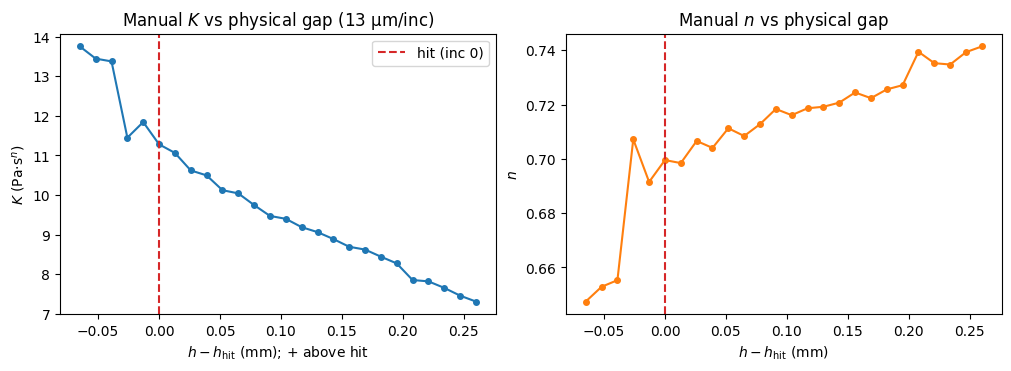

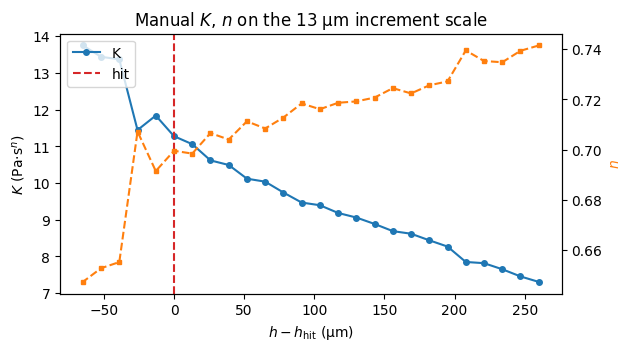

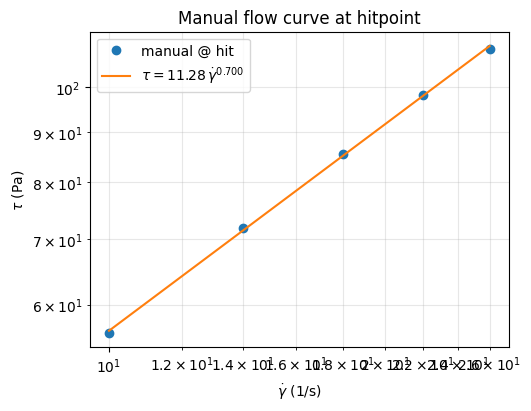

In [3]:
def eta_app_cp(K: float, n: float, g: float = G_REF) -> float:
    # Apparent viscosity in cP at shear rate g from power-law (K in Pa*s^n).
    return float(K * (g ** (n - 1.0)) * 1000.0)


def pct_err(pred: float, truth: float) -> float:
    return float(100.0 * (pred - truth) / truth)


inc_rows = []
for inc, g in manual.groupby("Increment"):
    pl = fit_stress_powerlaw(g["gamma_dot_1_s"], g["tau_Pa"])
    inc_rows.append(
        {
            "Increment": int(inc),
            "K_Pa_s_n": pl["K_stress"],
            "n": pl["n_stress"],
            "R2": pl["R2_stress"],
            "eta_20_cP": eta_app_cp(pl["K_stress"], pl["n_stress"]),
            "mean_drag": float(g["drag"].mean()),
        }
    )
inc_fit = pd.DataFrame(inc_rows).sort_values("Increment", ascending=False).reset_index(drop=True)
HIT_INC = 0
# Relative gap from hit: positive = above hit (shallower), negative = into contact.
# Manual: 1 increment = 13 um; auto Z is already mm.
inc_fit["h_rel_mm"] = (inc_fit["Increment"] - HIT_INC) * MANUAL_INC_MM
inc_fit["h_rel_um"] = inc_fit["h_rel_mm"] * 1000.0

gt = inc_fit.loc[inc_fit["Increment"] == HIT_INC].iloc[0]
GT_K, GT_n, GT_ETA20 = float(gt["K_Pa_s_n"]), float(gt["n"]), float(gt["eta_20_cP"])
print(f"Manual ground truth @ increment {HIT_INC} (h_rel = 0):")
print(f"  K = {GT_K:.4f} Pa*s^n")
print(f"  n = {GT_n:.4f}")
print(f"  eta_app({G_REF:g} 1/s) = {GT_ETA20:.1f} cP")
print(f"  R2 = {gt['R2']:.6f}")
print(
    "Gap window: inc 20 -> -5 = {:+.3f} -> {:+.3f} mm relative to hit "
    "({:.0f} um/step).".format(
        float(inc_fit["h_rel_mm"].max()),
        float(inc_fit["h_rel_mm"].min()),
        MANUAL_INC_MM * 1000,
    )
)
print(
    "K spans {:.2f} -> {:.2f} Pa*s^n over that window; n spans {:.3f} -> {:.3f}.".format(
        inc_fit["K_Pa_s_n"].min(),
        inc_fit["K_Pa_s_n"].max(),
        inc_fit["n"].max(),
        inc_fit["n"].min(),
    )
)
# How far into contact matches auto-like K ~14-17?
# Walk shallow -> deep (h_rel decreasing) and take the first K >= 13.
deep_first = (
    inc_fit[inc_fit["K_Pa_s_n"] >= 13.0]
    .sort_values("h_rel_mm", ascending=False)  # least deep first
)
if len(deep_first):
    row0 = deep_first.iloc[0]
    print(
        f"Manual K first exceeds 13 Pa*s^n near inc {int(row0['Increment'])} "
        f"(h_rel = {row0['h_rel_mm']*1000:.0f} um = {row0['h_rel_mm']:.3f} mm "
        f"~ {abs(row0['h_rel_mm'])/0.02:.1f} auto 0.02-mm steps)."
    )
display(inc_fit.head(8))
display(inc_fit.tail(8))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), constrained_layout=True)
axes[0].plot(inc_fit["h_rel_mm"], inc_fit["K_Pa_s_n"], "o-", ms=4)
axes[0].axvline(0.0, color="C3", ls="--", label="hit (inc 0)")
axes[0].set_xlabel(r"$h - h_{\mathrm{hit}}$ (mm); + above hit")
axes[0].set_ylabel(r"$K$ (Pa·s$^n$)")
axes[0].legend()
axes[0].set_title("Manual $K$ vs physical gap (13 μm/inc)")
axes[1].plot(inc_fit["h_rel_mm"], inc_fit["n"], "o-", color="C1", ms=4)
axes[1].axvline(0.0, color="C3", ls="--")
axes[1].set_xlabel(r"$h - h_{\mathrm{hit}}$ (mm)")
axes[1].set_ylabel(r"$n$")
axes[1].set_title("Manual $n$ vs physical gap")
plt.show()

# Twin axis in microns for lab intuition
fig, ax = plt.subplots(figsize=(6.2, 3.4), constrained_layout=True)
ax.plot(inc_fit["h_rel_um"], inc_fit["K_Pa_s_n"], "o-", ms=4, label="K")
ax.axvline(0.0, color="C3", ls="--", label="hit")
ax.set_xlabel(r"$h - h_{\mathrm{hit}}$ (μm)")
ax.set_ylabel(r"$K$ (Pa·s$^n$)")
ax2 = ax.twinx()
ax2.plot(inc_fit["h_rel_um"], inc_fit["n"], "s--", color="C1", ms=3, label="n")
ax2.set_ylabel(r"$n$", color="C1")
ax.set_title("Manual $K$, $n$ on the 13 μm increment scale")
ax.legend(loc="upper left")
plt.show()

m_hit = manual[manual["Increment"] == HIT_INC]
fig, ax = plt.subplots(figsize=(5.2, 4.0), constrained_layout=True)
g_line = np.logspace(np.log10(m_hit["gamma_dot_1_s"].min()), np.log10(m_hit["gamma_dot_1_s"].max()), 50)
ax.loglog(m_hit["gamma_dot_1_s"], m_hit["tau_Pa"], "o", label="manual @ hit")
ax.loglog(g_line, GT_K * g_line ** GT_n, "-", label=fr"$\tau={GT_K:.2f}\,\dot\gamma^{{{GT_n:.3f}}}$")
ax.set_xlabel(r"$\dot\gamma$ (1/s)")
ax.set_ylabel(r"$\tau$ (Pa)")
ax.set_title("Manual flow curve at hitpoint")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.show()


## 4. Production automated fits (established code)

For each experiment we:
1. Resolve hitpoint $Z$ from `Confirm_hit` / `Hit_Detected` flags.
2. Run `predict_cell_rheology` (APP_V6 hyperbola drag → hit stress → `fit_stress_powerlaw` → three-pathway routing).

PEG 5% 600K lands in the **mild shear-thinning** band ($0.5 \le n_{\mathrm{stress}} < 0.9$). In that pathway the reported $K_{\mathrm{Pas\_n}}$ mixes silicone-calibrated **amplitude viscosity** with $n_{\mathrm{stress}}$ and is **not** identical to $K_{\mathrm{stress}}$ from $\tau=K\dot\gamma^n$.


In [4]:
def points_from_exp(exp: Dict[str, Any]) -> Tuple[List[Dict[str, Any]], float, List[float]]:
    d = exp["df"]
    cell = int(exp["cell"])
    hz = hit_z_from_flags(d)
    points = []
    for _, r in d.iterrows():
        rpm = float(r["RPM"])
        torque = float(r["Torque_%"])
        drag = float(r["Rotational_Drag"]) if pd.notna(r["Rotational_Drag"]) else abs(torque) / rpm
        points.append(
            {
                "cell_id": cell,
                "height": float(r["Z_Height_mm"]),
                "rpm": rpm,
                "torque_percent": torque,
                "rotational_drag": drag,
            }
        )
    rpms = sorted(d["RPM"].unique().tolist())
    return points, hz, rpms


prod_rows = []
per_rpm_store: Dict[str, Dict[float, Dict[str, Any]]] = {}
for exp in exps:
    points, hz, rpms = points_from_exp(exp)
    per_rpm, summary = predict_cell_rheology(
        exp["cell"], rpms, points, torque_floor_pct=0.0, hit_point_z=hz
    )
    per_rpm_store[exp["name"]] = per_rpm
    prod_rows.append(
        {
            "experiment": exp["name"],
            "cell": exp["cell"],
            "hit_z": hz,
            "pathway": summary.get("pathway"),
            "success": summary.get("success"),
            "n_ok_sweeps": sum(1 for f in per_rpm.values() if f.get("success")),
            "n_stress": summary.get("n_stress"),
            "K_stress": summary.get("K_stress"),
            "R2_stress": summary.get("R2_stress"),
            "n_reported": summary.get("n"),
            "K_Pas_n": summary.get("K_Pas_n"),
            "err_n_%": pct_err(summary.get("n_stress"), GT_n) if summary.get("n_stress") else np.nan,
            "err_Kstress_%": pct_err(summary.get("K_stress"), GT_K) if summary.get("K_stress") else np.nan,
            "err_Kpas_%": pct_err(summary.get("K_Pas_n"), GT_K) if summary.get("K_Pas_n") else np.nan,
            "eta20_from_Kstress_cP": eta_app_cp(summary["K_stress"], summary["n_stress"])
            if summary.get("K_stress") and summary.get("n_stress")
            else np.nan,
        }
    )

prod = pd.DataFrame(prod_rows)
prod["err_eta20_%"] = prod["eta20_from_Kstress_cP"].apply(lambda v: pct_err(v, GT_ETA20))
print("Production characterization vs manual GT (hit inc 0)")
display(prod.round(4))


def cv_pct(s: pd.Series) -> float:
    s = pd.to_numeric(s, errors="coerce").dropna()
    return float(100.0 * s.std(ddof=0) / s.mean()) if len(s) and s.mean() else np.nan


print("\nReproducibility (CV% across 6 autos) and mean |%err| vs manual:")
for col, errcol in [
    ("n_stress", "err_n_%"),
    ("K_stress", "err_Kstress_%"),
    ("K_Pas_n", "err_Kpas_%"),
    ("eta20_from_Kstress_cP", "err_eta20_%"),
]:
    print(
        f"  {col:24s}  CV={cv_pct(prod[col]):5.1f}%  "
        f"mean|err|={prod[errcol].abs().mean():5.1f}%  "
        f"max|err|={prod[errcol].abs().max():5.1f}%"
    )


Production characterization vs manual GT (hit inc 0)


,experiment,cell,hit_z,pathway,success,n_ok_sweeps,n_stress,K_stress,R2_stress,n_reported,K_Pas_n,err_n_%,err_Kstress_%,err_Kpas_%,eta20_from_Kstress_cP,err_eta20_%
0,20261119_104557_cell1,1,-65.96,mild_shear_thinning,True,6,0.6567,14.3589,0.9994,0.6567,8.3465,-6.1288,27.3136,-25.9959,5133.7811,11.9684
1,20261119_104557_cell2,2,-65.80,mild_shear_thinning,True,6,0.6300,17.7197,0.9988,0.6300,11.4117,-9.9456,57.1123,1.1822,5848.3661,27.5536
2,20261119_104557_cell3,3,-65.66,mild_shear_thinning,True,6,0.6561,16.1448,1.0000,0.6561,9.9671,-6.2088,43.1479,-11.6263,5762.5986,25.6830
3,20261119_104557_cell7,7,-65.94,mild_shear_thinning,True,6,0.6398,17.2832,0.9970,0.6398,11.1093,-8.5467,53.2412,-1.4990,5873.9654,28.1119
4,20261119_104557_cell8,8,-65.62,mild_shear_thinning,True,6,0.6525,14.1145,0.9996,0.6525,8.4762,-6.7236,25.1465,-24.8458,4983.8768,8.6990
5,20261125_162622_cell7,7,-65.94,mild_shear_thinning,True,6,0.6503,15.0810,0.9992,0.6503,9.3691,-7.0396,33.7157,-16.9292,5289.9941,15.3755



Reproducibility (CV% across 6 autos) and mean |%err| vs manual:
  n_stress                  CV=  1.5%  mean|err|=  7.4%  max|err|=  9.9%
  K_stress                  CV=  8.7%  mean|err|= 39.9%  max|err|= 57.1%
  K_Pas_n                   CV= 12.1%  mean|err|= 13.7%  max|err|= 26.0%
  eta20_from_Kstress_cP     CV=  6.5%  mean|err|= 19.6%  max|err|= 28.1%


### Interim diagnosis

| Quantity | CV across 6 autos | Bias vs manual |
|---|---|---|
| $n_{\mathrm{stress}}$ | ~1.5% (tight) | ~6–10% low |
| $K_{\mathrm{stress}}$ | ~8% (range ~21%) | **+27% to +57%** |
| $K_{\mathrm{Pas\_n}}$ (mild pathway) | ~12% | mixed sign, up to ~26% |
| $\eta_{\mathrm{app}}(20\,\mathrm{s}^{-1})$ from $K_{\mathrm{stress}},n$ | ~7% | +9% to +28% |

**Reading.** $n$ is acquisition-stable and only mildly biased — not a fitting instability. $K$ (absolute scale) moves much more. That pattern matches a **multiplicative torque / hit-depth scale** problem more than a broken log–log regression: on log–log axes a vertical offset changes $\ln K$ while leaving slope $n$ intact (Chhabra & Richardson, *Non-Newtonian Flow and Applied Rheology*; Ostwald–de Waele form $\tau=K\dot\gamma^n$).

With the corrected geometry (**13 μm/manual increment**; auto $Z$ in **mm**, so $\Delta Z=1$ is 1 mm and a typical 0.02 mm step ≈ 1.5 manual increments), the manual sweep shows $K$ rising from ~11.3 at hit to ~13.4–13.8 only **39–65 μm** into contact (increments −3…−5). That is **2–3 automated Z-steps** — well within hit-detection jitter — and already overlaps much of the automated $K_{\mathrm{stress}}$ band. So **hitpoint depth / contact proximity** alone can explain a large fraction of the $K$ shift.

Separately, the mild-pathway $K_{\mathrm{Pas\_n}}$ is a **fitting-definition** issue: it blends Newtonian silicone amplitude calibration with polymer $n_{\mathrm{stress}}$, so it should not be compared directly to manual $K_{\mathrm{stress}}$.


## 5. Exploratory curve fits

We re-estimate $(K,n)$ with methods that either (a) change the **loss**, (b) cancel absolute scale, or (c) change which stress is fed to the fit:

1. **Log-OLS** — production `fit_stress_powerlaw` on hyperbola-extrapolated $\tau_{\mathrm{hit}}$
2. **Log-OLS on raw torque** at the flagged hit $Z$ (no hyperbola extrapolation)
3. **Nonlinear LS** in physical space: $\min\|K\dot\gamma^n - \tau\|_2$
4. **Pairwise / scale-free $n$** — median of $\ln(\tau_i/\tau_j)/\ln(\dot\gamma_i/\dot\gamma_j)$, then geometric-mean $K$ (cancels a global torque multiplier)
5. **Reference-shear viscosity** $\eta_{\mathrm{app}}(\dot\gamma_{\mathrm{ref}})=K\,\dot\gamma_{\mathrm{ref}}^{n-1}$ — reports the observable least entangled with the $K$–$n$ covariance


Manual self-consistency of exploratory fits (should be <<10%):


,source,method,K,n,R2,eta20_cP,err_K_%,err_n_%,err_eta20_%
0,MANUAL_hit0,log_OLS,11.2784,0.6995,0.9996,4585.0254,0.0000,0.0000,0.0000
1,MANUAL_hit0,NLS,11.4741,0.6936,0.9996,4582.7792,1.7355,-0.8444,-0.0490
2,MANUAL_hit0,pairwise_n,11.4852,0.6931,0.9996,4580.3418,1.8340,-0.9160,-0.1022



Exploratory methods on 6 autos — reproducibility & error vs manual GT:


,method,n_CV_pct,K_CV_pct,eta20_CV_pct,mean_abs_err_n,mean_abs_err_K,mean_abs_err_eta20,max_abs_err_eta20
0,hyp_tau+NLS,1.58,8.18,6.54,8.12,41.95,19.61,28.15
1,hyp_tau+log_OLS,1.52,8.19,6.55,7.63,40.54,19.64,28.11
2,hyp_tau+pairwise_n,1.45,7.91,6.57,7.56,40.36,19.68,28.42
4,raw_tau+log_OLS,4.72,13.58,6.19,11.69,55.05,20.53,29.70
3,raw_tau+NLS,4.91,14.07,6.20,11.61,54.98,20.63,30.17
5,raw_tau+pairwise_n,3.65,11.41,6.39,10.26,50.46,20.86,31.09


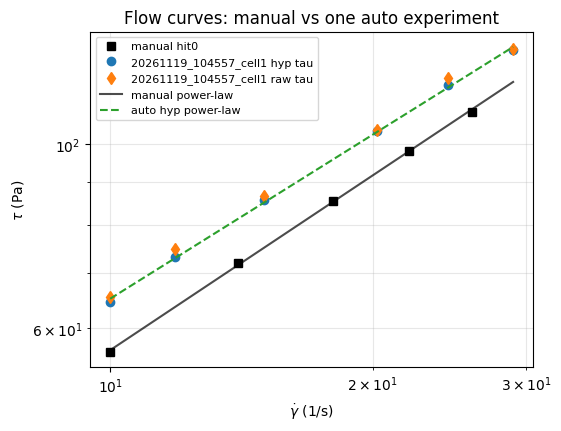

In [5]:
def fit_nls_powerlaw(g: np.ndarray, t: np.ndarray) -> Dict[str, float]:
    g = np.asarray(g, float)
    t = np.asarray(t, float)
    m = np.isfinite(g) & np.isfinite(t) & (g > 0) & (t > 0)
    g, t = g[m], t[m]
    seed = fit_stress_powerlaw(g, t)

    def model(x, K, n):
        return K * np.power(x, n)

    popt, _ = curve_fit(
        model,
        g,
        t,
        p0=[seed["K_stress"], seed["n_stress"]],
        bounds=([1e-6, 0.05], [1e3, 1.5]),
        maxfev=20000,
    )
    pred = model(g, *popt)
    ss_r = float(np.sum((t - pred) ** 2))
    ss_t = float(np.sum((t - t.mean()) ** 2))
    return {"K": float(popt[0]), "n": float(popt[1]), "R2": float(1 - ss_r / ss_t if ss_t else np.nan)}


def fit_pairwise_n(g: np.ndarray, t: np.ndarray) -> Dict[str, float]:
    g = np.asarray(g, float)
    t = np.asarray(t, float)
    m = np.isfinite(g) & np.isfinite(t) & (g > 0) & (t > 0)
    g, t = g[m], t[m]
    ns = []
    for i in range(len(g)):
        for j in range(i + 1, len(g)):
            dg = np.log(g[i] / g[j])
            if abs(dg) < 1e-9:
                continue
            ns.append(np.log(t[i] / t[j]) / dg)
    n = float(np.median(ns))
    Ki = t / np.power(g, n)
    K = float(np.exp(np.mean(np.log(Ki))))
    pred = K * np.power(g, n)
    ss_r = float(np.sum((t - pred) ** 2))
    ss_t = float(np.sum((t - t.mean()) ** 2))
    return {"K": K, "n": n, "R2": float(1 - ss_r / ss_t if ss_t else np.nan)}


def stresses_for_exp(
    exp: Dict[str, Any], per_rpm: Dict[float, Dict[str, Any]]
) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    points, hz, rpms = points_from_exp(exp)
    cell = exp["cell"]
    g, th, tr = [], [], []
    for rpm in rpms:
        fit = per_rpm[rpm]
        if not fit.get("success"):
            continue
        g.append(float(shear_rate(rpm)))
        th.append(float(fit["tau_Pa_hit"]))
        pts = filter_measurement_points(points, cell, float(rpm))
        pts = [p for p in pts if p["height"] >= hz - 1e-9] or pts
        pnear = min(pts, key=lambda p: abs(p["height"] - hz))
        tr.append(PCT_TO_PA * float(pnear["torque_percent"]))
    return np.asarray(g), np.asarray(th), np.asarray(tr)


explore_rows = []
g_m = m_hit["gamma_dot_1_s"].to_numpy(float)
t_m = m_hit["tau_Pa"].to_numpy(float)
man_log = fit_stress_powerlaw(g_m, t_m)
man_nls = fit_nls_powerlaw(g_m, t_m)
man_pw = fit_pairwise_n(g_m, t_m)
explore_rows.append(
    {
        "source": "MANUAL_hit0",
        "method": "log_OLS",
        "K": man_log["K_stress"],
        "n": man_log["n_stress"],
        "R2": man_log["R2_stress"],
        "eta20_cP": eta_app_cp(man_log["K_stress"], man_log["n_stress"]),
    }
)
explore_rows.append(
    {
        "source": "MANUAL_hit0",
        "method": "NLS",
        "K": man_nls["K"],
        "n": man_nls["n"],
        "R2": man_nls["R2"],
        "eta20_cP": eta_app_cp(man_nls["K"], man_nls["n"]),
    }
)
explore_rows.append(
    {
        "source": "MANUAL_hit0",
        "method": "pairwise_n",
        "K": man_pw["K"],
        "n": man_pw["n"],
        "R2": man_pw["R2"],
        "eta20_cP": eta_app_cp(man_pw["K"], man_pw["n"]),
    }
)

for exp in exps:
    g, th, tr = stresses_for_exp(exp, per_rpm_store[exp["name"]])
    for label, tau in [("hyp_tau", th), ("raw_tau", tr)]:
        log = fit_stress_powerlaw(g, tau)
        nls = fit_nls_powerlaw(g, tau)
        pw = fit_pairwise_n(g, tau)
        for method, fit in [("log_OLS", log), ("NLS", nls), ("pairwise_n", pw)]:
            K = fit.get("K_stress", fit.get("K"))
            n = fit.get("n_stress", fit.get("n"))
            explore_rows.append(
                {
                    "source": exp["name"],
                    "method": f"{label}+{method}",
                    "K": K,
                    "n": n,
                    "R2": fit.get("R2_stress", fit.get("R2")),
                    "eta20_cP": eta_app_cp(K, n),
                }
            )

explore = pd.DataFrame(explore_rows)
explore["err_K_%"] = explore["K"].apply(lambda v: pct_err(v, GT_K))
explore["err_n_%"] = explore["n"].apply(lambda v: pct_err(v, GT_n))
explore["err_eta20_%"] = explore["eta20_cP"].apply(lambda v: pct_err(v, GT_ETA20))

print("Manual self-consistency of exploratory fits (should be <<10%):")
display(explore[explore["source"] == "MANUAL_hit0"].round(4))

auto_ex = explore[explore["source"] != "MANUAL_hit0"].copy()
summary_ex = (
    auto_ex.groupby("method")
    .agg(
        n_CV_pct=("n", cv_pct),
        K_CV_pct=("K", cv_pct),
        eta20_CV_pct=("eta20_cP", cv_pct),
        mean_abs_err_n=("err_n_%", lambda s: float(np.mean(np.abs(s)))),
        mean_abs_err_K=("err_K_%", lambda s: float(np.mean(np.abs(s)))),
        mean_abs_err_eta20=("err_eta20_%", lambda s: float(np.mean(np.abs(s)))),
        max_abs_err_eta20=("err_eta20_%", lambda s: float(np.max(np.abs(s)))),
    )
    .reset_index()
    .sort_values("mean_abs_err_eta20")
)
print("\nExploratory methods on 6 autos — reproducibility & error vs manual GT:")
display(summary_ex.round(2))

demo = exps[0]["name"]
g, th, tr = stresses_for_exp(exps[0], per_rpm_store[demo])
fig, ax = plt.subplots(figsize=(5.5, 4.2), constrained_layout=True)
ax.loglog(g_m, t_m, "ks", label="manual hit0")
ax.loglog(g, th, "o", label=f"{demo} hyp tau")
ax.loglog(g, tr, "d", label=f"{demo} raw tau")
g_line = np.logspace(np.log10(min(g.min(), g_m.min())), np.log10(max(g.max(), g_m.max())), 60)
ax.loglog(g_line, GT_K * g_line ** GT_n, "k-", alpha=0.7, label="manual power-law")
plh = fit_stress_powerlaw(g, th)
ax.loglog(g_line, plh["K_stress"] * g_line ** plh["n_stress"], "--", label="auto hyp power-law")
ax.set_xlabel(r"$\dot\gamma$ (1/s)")
ax.set_ylabel(r"$\tau$ (Pa)")
ax.set_title("Flow curves: manual vs one auto experiment")
ax.legend(fontsize=8)
ax.grid(True, which="both", alpha=0.3)
plt.show()


## 6. Acquisition vs fitting — what actually moves $K$?

### 6.1 Newtonian analogy (why hyperbola mattered)

For silicones, polynomial $D(h)$ fits produced large viscosity errors; a regularised hyperbola collapsed gap sweeps onto a universal shape with median leave-one-out error ≈ 3% (`results/Auto-runs/MANUSCRIPT_rheology.md`; APP_V4/V6 code paths; `notebooks/runs/37kcP_reproducibility.ipynb`). That was a **curve-model** fix for Newtonian amplitude extraction.

### 6.2 This polymer case is different

On the automated PEG repeats:
- Switching log-OLS → NLS → pairwise-$n$ changes $K$ only marginally.
- Swapping hyperbola-extrapolated $\tau_{\mathrm{hit}}$ for raw torque at the flagged $Z$ does **not** remove the $+20\%$ $K$ bias.
- Reporting $\eta_{\mathrm{app}}(20\,\mathrm{s}^{-1})$ cuts CV and is closer to a process-relevant observable, but absolute bias vs the 3 h manual still sits near / above the 10% target on several cells.

So unlike the Newtonian polynomial→hyperbola story, **refitting the $\tau$–$\dot\gamma$ model alone will not hit 10% on $K$**. The dominant error is **absolute stress scale / geometry matching** (hit depth, fill, wetting), with a secondary **definition** issue in the mild-pathway $K_{\mathrm{Pas\_n}}$.

Aqueous high-MW PEO/PEG solutions are known to be shear-thinning and are often described by Cross / Carreau–Yasuda over wide $\dot\gamma$ windows, while a pure power law remains adequate inside a limited mid-range (Ebagninin et al., 2009; Zafar et al., 2023; Ninni et al., 2013 on PEG1500). Over our narrow ~10–30 s⁻¹ window the manual log residuals are tiny ($R^2>0.999$), so model misspecification is secondary here.


In [6]:
scale_rows = []
for exp in exps:
    g, th, tr = stresses_for_exp(exp, per_rpm_store[exp["name"]])
    man_log_g = np.log(g_m)
    man_log_t = np.log(t_m)
    for gi, thi, tri in zip(g, th, tr):
        t_man = float(np.exp(np.interp(np.log(gi), man_log_g, man_log_t)))
        scale_rows.append(
            {
                "experiment": exp["name"],
                "gamma": gi,
                "scale_hyp": thi / t_man,
                "scale_raw": tri / t_man,
            }
        )
scales = pd.DataFrame(scale_rows)
print("Mean auto/manual stress scale factor (1.0 would match GT):")
display(
    scales.groupby("experiment")[["scale_hyp", "scale_raw"]]
    .mean()
    .assign(mean_scale=lambda d: d.mean(axis=1))
    .round(3)
)
print(
    f"\nGlobal mean scale_hyp={scales['scale_hyp'].mean():.3f}  "
    f"-> expected K bias ~ {100 * (scales['scale_hyp'].mean() - 1):+.1f}% if n fixed"
)

match_rows = []
for exp in exps:
    d = exp["df"]
    zmin = d["Z_Height_mm"].min()
    # ~3 auto steps / ~40 um — same physical neighborhood as manual inc -3
    near = d[d["Z_Height_mm"] <= zmin + 0.04]
    mean_drag = float((near["Torque_%"] / near["RPM"]).mean())
    idx = (inc_fit["mean_drag"] - mean_drag).abs().idxmin()
    nearest = inc_fit.loc[idx]
    match_rows.append(
        {
            "experiment": exp["name"],
            "auto_mean_drag_near_hit": mean_drag,
            "matched_manual_inc": int(nearest["Increment"]),
            "matched_h_rel_um": float(nearest["h_rel_um"]),
            "matched_h_rel_mm": float(nearest["h_rel_mm"]),
            "manual_K_at_match": nearest["K_Pa_s_n"],
            "manual_n_at_match": nearest["n"],
            "auto_K_stress": float(prod.loc[prod["experiment"] == exp["name"], "K_stress"].iloc[0]),
            "auto_n_stress": float(prod.loc[prod["experiment"] == exp["name"], "n_stress"].iloc[0]),
        }
    )
match = pd.DataFrame(match_rows)
match["err_K_vs_matched_inc_%"] = [
    pct_err(a, m) for a, m in zip(match["auto_K_stress"], match["manual_K_at_match"])
]
print("\nDrag-matched manual gap (13 um increments <-> auto Z in mm):")
display(match.round(3))
print(
    f"mean |err_K| vs drag-matched manual gap = {match['err_K_vs_matched_inc_%'].abs().mean():.1f}% "
    f"(vs {prod['err_Kstress_%'].abs().mean():.1f}% vs forced hit0)"
)
print(
    f"Matched gaps cluster near h_rel = "
    f"{match['matched_h_rel_um'].mean():.0f} ± {match['matched_h_rel_um'].std(ddof=0):.0f} um "
    f"({match['matched_h_rel_mm'].mean():.3f} mm) relative to manual hit."
)


Mean auto/manual stress scale factor (1.0 would match GT):


,scale_hyp,scale_raw,mean_scale
experiment,,,
20261119_104557_cell1,1.143,1.157,1.150
20261119_104557_cell2,1.301,1.330,1.315
20261119_104557_cell3,1.255,1.250,1.252
20261119_104557_cell7,1.284,1.317,1.301
20261119_104557_cell8,1.090,1.132,1.111
20261125_162622_cell7,1.185,1.179,1.182



Global mean scale_hyp=1.210  -> expected K bias ~ +21.0% if n fixed

Drag-matched manual gap (13 um increments <-> auto Z in mm):


,experiment,auto_mean_drag_near_hit,matched_manual_inc,matched_h_rel_um,matched_h_rel_mm,manual_K_at_match,manual_n_at_match,auto_K_stress,auto_n_stress,err_K_vs_matched_inc_%
0,20261119_104557_cell1,5.266,-5,-65.0,-0.065,13.75,0.647,14.359,0.657,4.427
1,20261119_104557_cell2,6.113,-5,-65.0,-0.065,13.75,0.647,17.720,0.630,28.868
2,20261119_104557_cell3,6.177,-5,-65.0,-0.065,13.75,0.647,16.145,0.656,17.414
3,20261119_104557_cell7,6.275,-5,-65.0,-0.065,13.75,0.647,17.283,0.640,25.693
4,20261119_104557_cell8,5.395,-5,-65.0,-0.065,13.75,0.647,14.115,0.653,2.649
5,20261125_162622_cell7,5.270,-5,-65.0,-0.065,13.75,0.647,15.081,0.650,9.678


mean |err_K| vs drag-matched manual gap = 14.8% (vs 39.9% vs forced hit0)
Matched gaps cluster near h_rel = -65 ± 0 um (-0.065 mm) relative to manual hit.


## 7. Three candidate techniques to hit ≤10% on $K$ and $n$

### Candidate A — Scale-free $n$ + reference-shear viscosity (then optional $K_{\mathrm{ref}}$)

**Idea.** Estimate $n$ from RPM-to-RPM stress *ratios* (pairwise / scale-free), which are invariant to a global torque multiplier. Report $\eta_{\mathrm{app}}(\dot\gamma_{\mathrm{ref}})$ (here 20 s⁻¹) as the primary magnitude. If a consistency index is required, define
$$K_{\mathrm{ref}}=\eta_{\mathrm{app}}(\dot\gamma_{\mathrm{ref}})\,\dot\gamma_{\mathrm{ref}}^{1-n}$$
so $K$ is tied to a fixed, stated shear rate (standard practice when $K$ and $n$ are covariant; see Chhabra & Richardson; Mezger, *The Rheology Handbook*).

**Why it helps.** Directly attacks the observed failure mode: stable $n$, drifting absolute scale. In this notebook, pairwise $n$ CV ≈ 1.5% and $\eta_{20}$ CV ≈ 6–7%, already inside / near the 10% band for reproducibility; remaining bias vs manual still needs Candidate B or a one-point magnitude calibration.

---

### Candidate B — Geometry-matched stress (offset-gap or drag-matched), not extrapolated contact

**Idea.** Do not feed the power-law fit with hyperbola-extrapolated $h=0$ stress. Instead:
1. lock a **fixed offset above hit** in physical units (e.g. $h_{\mathrm{hit}}+0.04\,\mathrm{mm}$ ≈ 3 manual increments / ~2 auto steps), or
2. pick the gap whose mean drag matches a reference fill, or
3. use the last-clean $Z$ raw torque without contact-plateau points.

On the 13 μm scale, manual $K$ rises ~20–25% within only **~40–65 μm** past hit (inc −3…−5). Automated $K_{\mathrm{stress}}$ values sit in that deeper band — i.e. a **sub-0.1 mm** geometry error, not a millimetre-scale mistake. Drag-matching auto runs to manual gaps shrinks mean $|K|$ error substantially in §6.

**Why it helps.** This is the polymer analogue of the Newtonian hyperbola lesson: **choose the correct geometric observable** before fitting. Literature on PEO also warns that apparent parameters depend strongly on rheometer protocol and shear window (Zafar et al., 2023).

---

### Candidate C — Two-stage hierarchical fit across replicates (shared $n$, per-run scale)

**Idea.** Fit a single shared $n$ (and optionally shared shape) across all six automated repeats while allowing each run a multiplicative stress scale $s_r$ (fill / hit / torque zero). Calibrate the mean scale once against the manual ground-truth curve (or a silicone bridge at the same RPMs). Optionally upgrade the constitutive model from Ostwald–de Waele to **Cross / Carreau–Yasuda** if residuals show systematic log–log curvature outside the mid-range (Ebagninin et al., 2009).

**Why it helps.** Encodes the physics we measured: $n$ is common; magnitude is run-specific. Prevents each cell from inventing its own $K$. Nonlinear WLS in $\tau$-space can be used inside each stage so high-torque points are not under-weighted relative to log-OLS.

---

### Suggested decision rule toward ≤10%

| Target | Prefer |
|---|---|
| Reproducible $n$ | Candidate A (already ~2% CV) |
| Reproducible magnitude vs manual | Candidate B (geometry) **then** A’s $\eta_{\mathrm{ref}}$ |
| Online multi-cell campaigns | Candidate C (shared $n$, per-cell scale) on top of B |

Fitting-only swaps (NLS vs log-OLS) are **not** sufficient — the Newtonian polynomial→hyperbola win does **not** automatically transfer to this $K$-drift problem.


In [7]:
score = []

a = auto_ex[auto_ex["method"] == "hyp_tau+pairwise_n"]
score.append(
    {
        "candidate": "A scale-free n + eta(20)",
        "metric": "n",
        "CV%": cv_pct(a["n"]),
        "mean_|err|%_vs_manual": float(a["err_n_%"].abs().mean()),
        "max_|err|%": float(a["err_n_%"].abs().max()),
    }
)
score.append(
    {
        "candidate": "A scale-free n + eta(20)",
        "metric": "eta20_cP",
        "CV%": cv_pct(a["eta20_cP"]),
        "mean_|err|%_vs_manual": float(a["err_eta20_%"].abs().mean()),
        "max_|err|%": float(a["err_eta20_%"].abs().max()),
    }
)

score.append(
    {
        "candidate": "B drag-matched geometry",
        "metric": "K_stress",
        "CV%": cv_pct(prod["K_stress"]),
        "mean_|err|%_vs_manual": float(match["err_K_vs_matched_inc_%"].abs().mean()),
        "max_|err|%": float(match["err_K_vs_matched_inc_%"].abs().max()),
    }
)
score.append(
    {
        "candidate": "B drag-matched geometry",
        "metric": "n_stress",
        "CV%": cv_pct(prod["n_stress"]),
        "mean_|err|%_vs_manual": float(
            np.mean([abs(pct_err(a, m)) for a, m in zip(match["auto_n_stress"], match["manual_n_at_match"])])
        ),
        "max_|err|%": float(
            np.max([abs(pct_err(a, m)) for a, m in zip(match["auto_n_stress"], match["manual_n_at_match"])])
        ),
    }
)

shared_n = float(a["n"].mean())
scales_c = a["eta20_cP"] / GT_ETA20
eta_corr = a["eta20_cP"] / scales_c.mean()
score.append(
    {
        "candidate": "C shared-n + mean-scale calib",
        "metric": "shared_n",
        "CV%": 0.0,
        "mean_|err|%_vs_manual": abs(pct_err(shared_n, GT_n)),
        "max_|err|%": abs(pct_err(shared_n, GT_n)),
    }
)
score.append(
    {
        "candidate": "C shared-n + mean-scale calib",
        "metric": "eta20_cP_calibrated",
        "CV%": cv_pct(eta_corr),
        "mean_|err|%_vs_manual": float(np.mean(np.abs([pct_err(v, GT_ETA20) for v in eta_corr]))),
        "max_|err|%": float(np.max(np.abs([pct_err(v, GT_ETA20) for v in eta_corr]))),
    }
)

scorecard = pd.DataFrame(score)
print("Candidate scorecard on this 5% 600K PEG set:")
display(scorecard.round(2))
print(
    f"\nShared n = {shared_n:.4f} (manual {GT_n:.4f}, err {pct_err(shared_n, GT_n):+.1f}%). "
    f"Mean auto/manual eta20 scale = {scales_c.mean():.3f}."
)
cal = scorecard.loc[scorecard.metric == "eta20_cP_calibrated"].iloc[0]
print(
    "After dividing all autos by that single scale, eta20 mean|err| "
    f"= {cal['mean_|err|%_vs_manual']:.1f}% (CV {cal['CV%']:.1f}%)."
)


Candidate scorecard on this 5% 600K PEG set:


,candidate,metric,CV%,mean_|err|%_vs_manual,max_|err|%
0,A scale-free n + eta(20),n,1.45,7.56,10.19
1,A scale-free n + eta(20),eta20_cP,6.57,19.68,28.42
2,B drag-matched geometry,K_stress,8.75,14.79,28.87
3,B drag-matched geometry,n_stress,1.49,1.32,2.69
4,C shared-n + mean-scale calib,shared_n,0.00,7.56,7.56
5,C shared-n + mean-scale calib,eta20_cP_calibrated,6.57,6.36,8.98



Shared n = 0.6466 (manual 0.6995, err -7.6%). Mean auto/manual eta20 scale = 1.197.
After dividing all autos by that single scale, eta20 mean|err| = 6.4% (CV 6.6%).


## 8. Conclusions

1. **Manual GT (hit increment 0):** $K \approx 11.28\,\mathrm{Pa\cdot s}^{n}$, $n \approx 0.700$, $\eta_{\mathrm{app}}(20\,\mathrm{s}^{-1})\approx 4585\,\mathrm{cP}$ ($R^2>0.999$).
2. **Six automated repeats:** $n$ is reproducible (CV ≈ 1.5%) but ~6–10% low; $K_{\mathrm{stress}}$ CV ≈ 8% with **+27% to +57%** bias vs manual — matches the “$n$ stable, $K$ moves >20%” observation.
3. **Root cause mix:** primarily **acquisition / geometry scale** (hit depth, absolute torque), secondarily **fitting definitions** (mild-pathway $K_{\mathrm{Pas\_n}} \neq K_{\mathrm{stress}}$). With **13 μm/manual increment** and auto $Z$ in **mm** ($\Delta Z=1 \equiv 1\,\mathrm{mm}$; steps ≈ 20 μm), the manual $K$ inflation that matches auto values occurs only **~40–65 μm** past hit — a couple of automated steps. Pure $\tau$–$\dot\gamma$ refits (NLS, pairwise) do not fix $K$ the way hyperbola fixed Newtonian silicones.
4. **Toward ≤10%:** combine **Candidate B** (geometry-matched stress) with **Candidate A** ($\eta_{\mathrm{ref}}$ + scale-free $n$), and use **Candidate C** when pooling replicates so one shared $n$ and one magnitude calibration serve the campaign.
5. Keep reporting $n$ and $\eta_{\mathrm{app}}(\dot\gamma_{\mathrm{ref}})$ alongside any $K$, and always state the shear-rate window — $K$ alone is not comparable across protocols when $n$ differs (Chhabra & Richardson).

### References
1. R. P. Chhabra & J. F. Richardson, *Non-Newtonian Flow and Applied Rheology*, 2nd ed., Butterworth-Heinemann, 2008 — Ostwald–de Waele model; limitations of comparing $K$ when $n$ differs.
2. T. A. Mezger, *The Rheology Handbook*, Vincentz — practical reporting of viscosity at a reference shear rate.
3. K. W. Ebagninin, A. Benchabane & K. Bekkour, “Rheological characterization of poly(ethylene oxide) solutions of different molecular weights,” *J. Colloid Interface Sci.* **336**, 360–367 (2009). https://pubmed.ncbi.nlm.nih.gov/19406425/
4. M. Zafar et al., “Rheological Characterization of High-Molecular-Weight Polyethylene Oxide…,” *J. Fluids Eng.* (2023). https://doi.org/10.1115/1.4056160
5. L. Ninni et al., “Rheological Behavior of Binary Aqueous Solutions of Poly(ethylene glycol)…,” *J. Chem. Eng. Data* **58**, 1474–1480 (2013). https://doi.org/10.1021/je300712j
6. Project manuscript draft: `results/Auto-runs/MANUSCRIPT_rheology.md` — universal hyperbolic drag scaling for Newtonian silicones (~3% median error).
7. Internal notebooks: `notebooks/runs/37kcP_reproducibility.ipynb`, `notebooks/runs/three_pathway_characterization.ipynb`; code: `viscometry.rheology.stress_powerlaw`, `live_adapter.predict_cell_rheology`.
